# IMAP DATA ANALYSIS
##  *TODO LIST*

- [ ] Analysis of time-series data in chosen timespan,
- [ ] Analysis of the data distribution,
- [ ] Linear correlations between parameters from specific instrument,
- [ ] Linear correlations between parameters from different instruments,
- [ ] Non-linear correlations between parameters from specific instrument,
- [ ] Non-linear correlations between parameters from different instruments,
- [ ] PCA Analysis of data per instrument,
- [ ] TSNE Analysis of data per instrument,
- [ ] MI Analysis of data between instruments,

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import os
import cdflib

In [18]:
data_dir = "../raw_data/ARCHIVE/All"
cdf_files = []
other_files = []
for file in os.listdir(data_dir):
    filename = os.fsdecode(file)
    if filename.endswith(".cdf"):
        cdf_files.append(filename)
    else:
        other_files.append(filename)

print(cdf_files)
## to w pętle wjebać
cdf = cdflib.CDF(f"{data_dir}/imap_ialirt_l1_realtime_20260507_v001.cdf")




['imap_ialirt_l1_realtime_20260401_v001.cdf', 'imap_ialirt_l1_realtime_20260402_v001.cdf', 'imap_ialirt_l1_realtime_20260403_v001.cdf', 'imap_ialirt_l1_realtime_20260404_v001.cdf', 'imap_ialirt_l1_realtime_20260405_v001.cdf', 'imap_ialirt_l1_realtime_20260406_v001.cdf', 'imap_ialirt_l1_realtime_20260407_v001.cdf', 'imap_ialirt_l1_realtime_20260408_v001.cdf', 'imap_ialirt_l1_realtime_20260409_v001.cdf', 'imap_ialirt_l1_realtime_20260410_v001.cdf', 'imap_ialirt_l1_realtime_20260411_v001.cdf', 'imap_ialirt_l1_realtime_20260412_v001.cdf', 'imap_ialirt_l1_realtime_20260413_v001.cdf', 'imap_ialirt_l1_realtime_20260414_v001.cdf', 'imap_ialirt_l1_realtime_20260415_v001.cdf', 'imap_ialirt_l1_realtime_20260416_v001.cdf', 'imap_ialirt_l1_realtime_20260417_v001.cdf', 'imap_ialirt_l1_realtime_20260418_v001.cdf', 'imap_ialirt_l1_realtime_20260419_v001.cdf', 'imap_ialirt_l1_realtime_20260420_v001.cdf', 'imap_ialirt_l1_realtime_20260422_v001.cdf', 'imap_ialirt_l1_realtime_20260423_v001.cdf', 'imap_ial

In [19]:
info = cdf.cdf_info()
for var in info.zVariables:
    var_info = cdf.varinq(var)
    attrs = cdf.varattsget(var)
    print(f"\n{'=' * 80}")
    print(f"VARIABLE: {var}")
    print(f"{var_info}")
    print(f"ATTRIBUTES: {attrs}")
    print(f"{'=' * 80}")


VARIABLE: codice_hi_h
VDRInfo(Variable='codice_hi_h', Num=0, Var_Type='zVariable', Data_Type=44, Data_Type_Description='CDF_FLOAT', Num_Elements=1, Num_Dims=3, Dim_Sizes=[15, 4, 4], Sparse='No_sparse', Last_Rec=845, Rec_Vary=True, Dim_Vary=[-1, -1, -1], Compress=0, Pad=array([-1.e+30], dtype=float32), Block_Factor=1)
ATTRIBUTES: {'DEPEND_0': 'codice_hi_epoch', 'DISPLAY_TYPE': 'no_plot', 'FILLVAL': np.float32(-1e+31), 'FORMAT': 'F11.1', 'VALIDMIN': np.float32(0.0), 'VALIDMAX': np.float32(1e+08), 'VAR_TYPE': 'data', 'UNITS': 'counts / cm2-sr-s-MeV', 'dtype': 'float32', 'CATDESC': 'Proton flux from CoDICE-Hi in 15 energy bins between 0.02 to 3.62 MeV over 4 spin angles and 4 polar angles', 'FIELDNAM': 'H+ intensity', 'LABLAXIS': 'H+ intensity', 'DEPEND_1': 'codice_hi_energy_center', 'DEPEND_2': 'codice_hi_spin_sector', 'DEPEND_3': 'codice_hi_polar', 'VAR_NOTES': 'Energy ranges (MeV) are 0.0200 to 0.0283, 0.0283 to 0.0400, 0.0400 to 0.0566, 0.0566 to 0.0800, 0.0800 to 0.113, 0.113 to 0.16

### MAG
We are going to check how $B$ (magnitude) changes in relation to time and position of the IMAP satellite.

GSE explenation [here](https://www.researchgate.net/figure/The-diagram-shows-the-Geocentric-Solar-Ecliptic-GSE-coordinate-system-centered-at-the_fig1_334136287)


![GSE diagram](../res/GSE.png)


;isajous curves around the L1 point

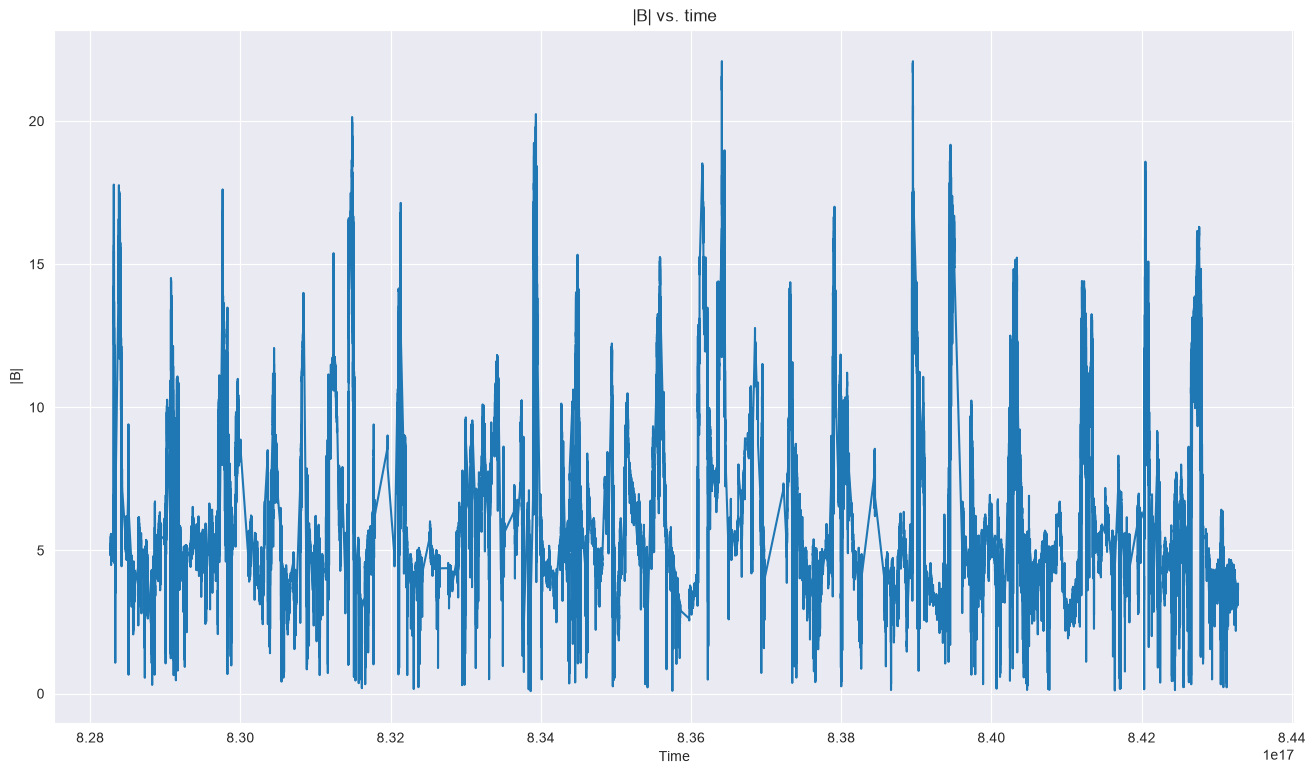

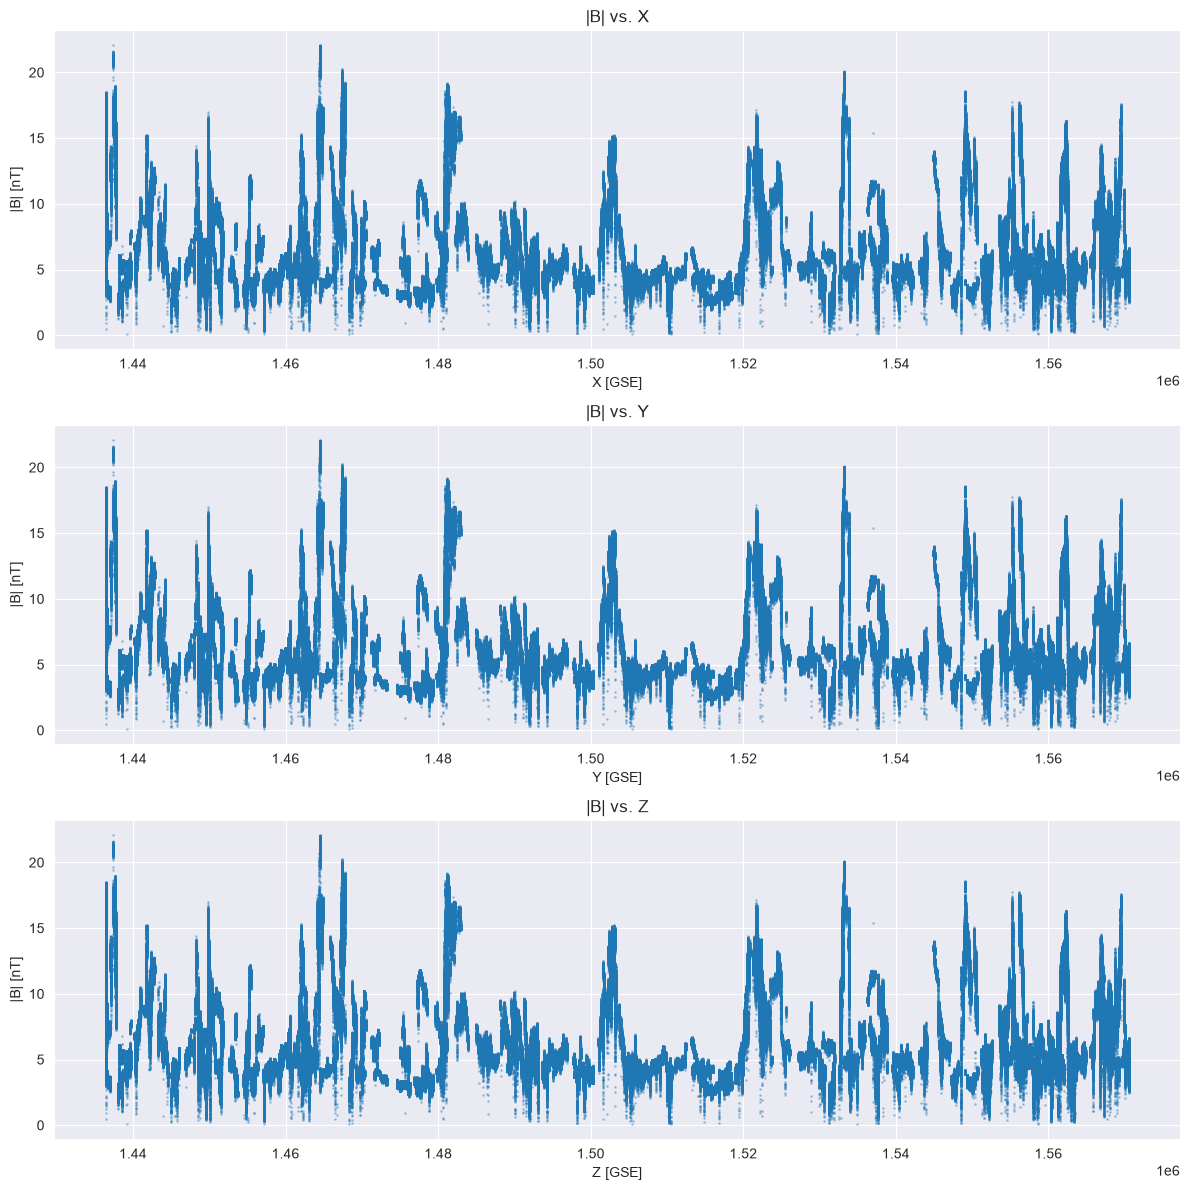

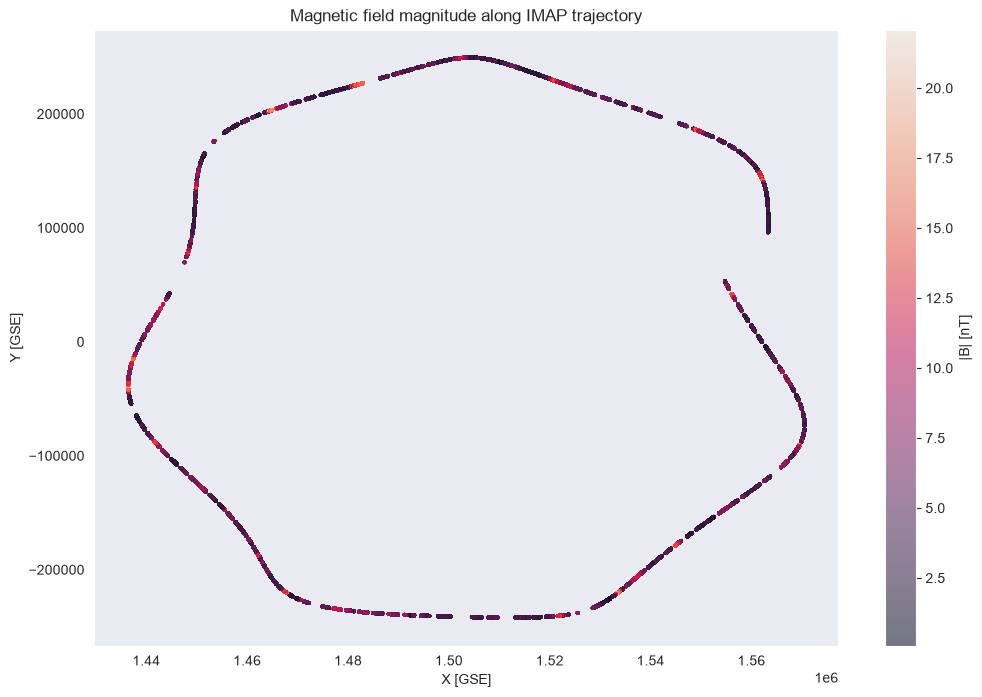

In [45]:
all_time = []
B_mag_all = []
all_position = []

for file in cdf_files:
    cdf = cdflib.CDF(f"{data_dir}/{file}")
    mag_epoch = cdf.varget("mag_epoch")
    mag_b_magnitude = cdf.varget("mag_b_magnitude")
    ephem_epoch = cdf.varget("ephemeris_epoch") # próbkowanie pozycji
    position_GSE = cdf.varget("sc_position_GSE") # pozycja GSE (Geocentric Solar Ecliptic)
    idx = np.argsort(ephem_epoch)
    ephem_epoch = ephem_epoch[idx]
    position_GSE = position_GSE[idx]
    x = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 0])
    y = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 1])
    z = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 2])
    position_interp = np.column_stack((x, y, z))
    all_time.append(mag_epoch) # czas rejestracji zmiany pola magnetycznego
    B_mag_all.append(mag_b_magnitude) # pole magnetyczne wokół imapa
    all_position.append(position_interp)

all_time = np.concatenate(all_time)
B_mag_all = np.concatenate(B_mag_all)
all_position = np.concatenate(all_position)
idx = np.argsort(all_time)
all_time = all_time[idx]
B_mag_all = B_mag_all[idx]
all_position = all_position[idx]
valid = np.isfinite(B_mag_all) & (B_mag_all != -1e31)
all_time = all_time[valid]
B_mag_all = B_mag_all[valid]
all_position = all_position[valid]

x = all_position[:, 0]
y = all_position[:, 1]
z = all_position[:, 2]
plt.figure(figsize=(16, 9))
plt.plot(all_time, B_mag_all)
plt.xlabel("Time")
plt.ylabel("|B|")
plt.title("|B| vs. time")
plt.show()
fig, axes = plt.subplots(3, 1, figsize=(12,12))
axes[0].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[0].set_xlabel("X [GSE]")
axes[0].set_ylabel("|B| [nT]")
axes[0].set_title("|B| vs. X")
axes[1].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[1].set_xlabel("Y [GSE]")
axes[1].set_ylabel("|B| [nT]")
axes[1].set_title("|B| vs. Y")
axes[2].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[2].set_xlabel("Z [GSE]")
axes[2].set_ylabel("|B| [nT]")
axes[2].set_title("|B| vs. Z")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
scatter = plt.scatter(x, y, c=B_mag_all, s=3, alpha=0.5)
plt.xlabel("X [GSE]")
plt.ylabel("Y [GSE]")
plt.title("Magnetic field magnitude along IMAP trajectory")
plt.colorbar(scatter, label="|B| [nT]")
plt.grid()
plt.show()

In [46]:
from scipy.signal import find_peaks
peaks, _ = find_peaks(y, distance=10000)
troughs, _ = find_peaks(-y, distance=10000)
print(all_time[peaks])
print(all_position[troughs])

[829465220367459840 830148363930732672 839658751838165248
 840404802932643712]
[[1570446.86626703  -66797.05538155   73956.20881895]
 [1562657.20331881 -121981.17064406   54098.8282219 ]
 [1513223.5        -242075.984375    -29331.390625  ]
 [1487879.84562043  233057.05378649   14756.66528915]]
